
# 1. Load the data


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)


In [ ]:
orders_df = pd.read_csv("olist_orders_dataset.csv", parse_dates=[
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date"])
items_df = pd.read_csv('olist_order_items_dataset.csv')
customers_df = pd.read_csv('olist_customers_dataset.csv')
products_df = pd.read_csv('olist_products_dataset.csv')
sellers_df = pd.read_csv('olist_sellers_dataset.csv')
translation_df = pd.read_csv('product_category_name_translation.csv')
payments_df = pd.read_csv('olist_order_payments_dataset.csv')


In [6]:
orders_df.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [7]:

items_df.head()


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [8]:

products_df.head()


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0



# 2.EDA


In [9]:

datasets = {'orders': orders_df, 'items': items_df, 'customers': customers_df,
            'products': products_df, 'sellers': sellers_df, 'category_translation': translation_df}

summary_df = pd.DataFrame({
    name: {'rows': df.shape[0], 'columns': df.shape[1],
           'missing values': df.isna().sum().sum(), 'duplicated rows': df.duplicated().sum()}
    for name, df in datasets.items()
}).T

summary_df


,rows,columns,missing values,duplicated rows
orders,99441,8,4908,0
items,112650,7,0,0
customers,99441,5,0,0
products,32951,9,2448,0
sellers,3095,4,0,0
category_translation,71,2,0,0


In [10]:
orders_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 13.0 MB


In [11]:
items_df.describe()


,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [12]:
products_df.describe()


,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000



# 3. Clean


In [13]:
orders_raw_rows = orders_df.shape[0]     

orders_df = orders_df.dropna(subset=['order_delivered_carrier_date', 'order_delivered_customer_date'])
print('orders:', orders_raw_rows, '->', orders_df.shape[0])

products_df['product_category_name'] = products_df['product_category_name'].fillna('unknown')
products_df = products_df.dropna(subset=['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm'])


orders: 99441 -> 96475


In [14]:

orders_df = orders_df.drop_duplicates()
items_df = items_df.drop_duplicates()
products_df = products_df.drop_duplicates()
customers_df = customers_df.drop_duplicates()
sellers_df = sellers_df.drop_duplicates()


In [15]:

orders_df = orders_df[orders_df['order_status'] == 'delivered'].copy()

products_df = products_df[(products_df['product_weight_g'] > 0) & (products_df['product_length_cm'] > 0) &
                          (products_df['product_height_cm'] > 0) & (products_df['product_width_cm'] > 0)].copy()

items_df = items_df[(items_df['price'] > 0) & (items_df['freight_value'] >= 0)].copy()


In [16]:

date_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']

orders_df[date_cols] = orders_df[date_cols].apply(pd.to_datetime)


In [17]:

wrong_dates = ((orders_df['order_delivered_carrier_date'] < orders_df['order_purchase_timestamp']) |
               (orders_df['order_delivered_customer_date'] < orders_df['order_delivered_carrier_date']))
print('Orders with impossible dates:', wrong_dates.sum())

orders_df = orders_df[~wrong_dates].copy()


Orders with impossible dates: 188


In [18]:

df = items_df.merge(orders_df, on='order_id')
df = df.merge(customers_df, on='customer_id')
df = df.merge(products_df, on='product_id')
df = df.merge(sellers_df, on='seller_id')

df = df.merge(translation_df, on='product_category_name', how='left')
df['product_category_name_english'] = df['product_category_name_english'].fillna(df['product_category_name'])

df['state_route'] = df['seller_state'] + '_' + df['customer_state']

df.shape


(109926, 31)


# How long does delivery take? (the two targets)



In [19]:

day = 60 * 60 * 24    

# Model 1 target: purchase -> carrier
df['days_purchase_to_carrier'] = (df['order_delivered_carrier_date'] - df['order_purchase_timestamp']).dt.total_seconds() / day

# Model 2 target: carrier -> customer
df['days_carrier_to_customer'] = (df['order_delivered_customer_date'] - df['order_delivered_carrier_date']).dt.total_seconds() / day

t1 = 'days_purchase_to_carrier'
t2 = 'days_carrier_to_customer'

target_names = {t1: 'Stage 1: seller to carrier', t2: 'Stage 2: carrier to customer'}

df[[t1, t2]].describe().round(2)


,days_purchase_to_carrier,days_carrier_to_customer
count,109926.00,109926.00
mean,3.29,9.20
std,3.61,8.61
min,0.00,0.00
25%,1.14,4.06
50%,2.23,7.06
75%,4.12,11.92
max,125.78,205.19


In [20]:

print(f"Stage 1: half of the products are handed to the carrier within {df[t1].median():.1f} days, and 9 out of 10 within {df[t1].quantile(0.9):.1f} days.")
print(f"Stage 2: half of the products reach the customer within {df[t2].median():.1f} days after pick-up, and 9 out of 10 within {df[t2].quantile(0.9):.1f} days.")


Stage 1: half of the products are handed to the carrier within 2.2 days, and 9 out of 10 within 6.6 days.
Stage 2: half of the products reach the customer within 7.1 days after pick-up, and 9 out of 10 within 18.5 days.



### Figure 1: How many days does the seller take to hand the product to the carrier?


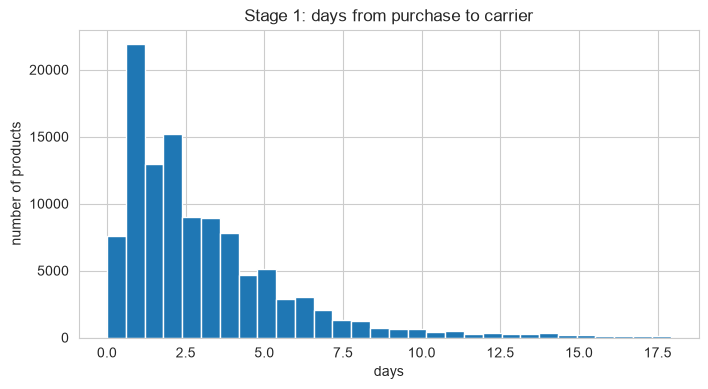

In [21]:

df[t1].plot(kind='hist', bins=30, range=(0, df[t1].quantile(0.99)), figsize=(8, 4), title='Stage 1: days from purchase to carrier')
plt.xlabel('days')
plt.ylabel('number of products')
plt.show()



### Figure 2: How many days does the carrier take to deliver the product?


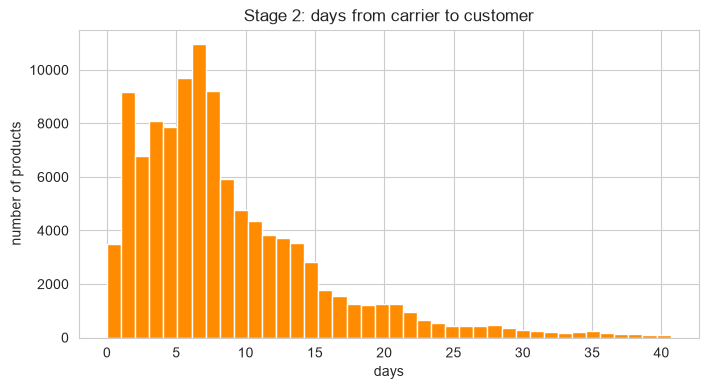

In [22]:

df[t2].plot(kind='hist', bins=40, range=(0, df[t2].quantile(0.99)), figsize=(8, 4), color='darkorange', title='Stage 2: days from carrier to customer')
plt.xlabel('days')
plt.ylabel('number of products')
plt.show()



# What do the products look like? (feature distributions)


In [23]:

num_features = ['product_weight_g', 'product_length_cm', 'product_height_cm',
                'product_width_cm', 'price', 'freight_value']

df[num_features].describe().round(1)


,product_weight_g,product_length_cm,product_height_cm,product_width_cm,price,freight_value
count,109926.0,109926.0,109926.0,109926.0,109926.0,109926.0
mean,2090.6,30.1,16.6,23.0,120.0,19.9
std,3743.1,16.1,13.4,11.7,182.4,15.7
min,2.0,7.0,2.0,6.0,0.8,0.0
25%,300.0,18.0,8.0,15.0,39.9,13.1
50%,700.0,25.0,13.0,20.0,74.9,16.2
75%,1800.0,38.0,20.0,30.0,134.5,21.2
max,40425.0,105.0,105.0,118.0,6735.0,409.7



### Figure 3: How heavy are the products?


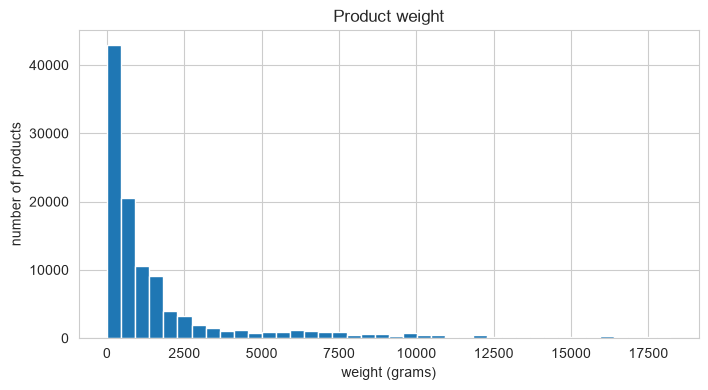

In [24]:

df['product_weight_g'].plot(kind='hist', bins=40, range=(0, df['product_weight_g'].quantile(0.99)), figsize=(8, 4), title='Product weight')
plt.xlabel('weight (grams)')
plt.ylabel('number of products')
plt.show()



### Figure 4: How much do the products cost?


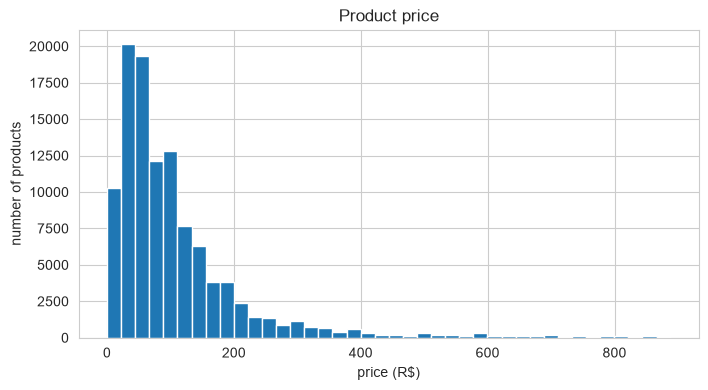

In [25]:

df['price'].plot(kind='hist', bins=40, range=(0, df['price'].quantile(0.99)), figsize=(8, 4), title='Product price')
plt.xlabel('price (R$)')
plt.ylabel('number of products')
plt.show()



### Figure 5: How much is the shipping cost (freight)?


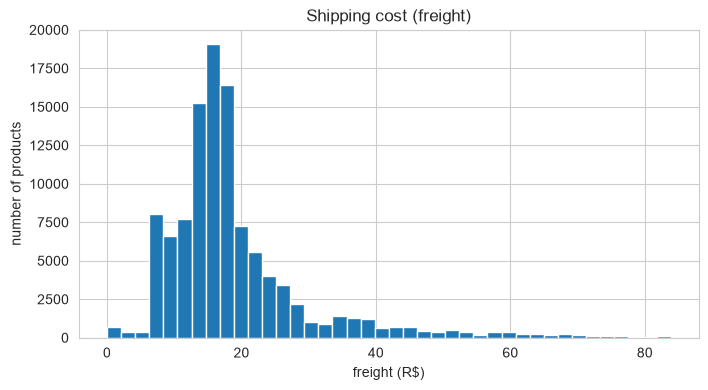

In [26]:

df['freight_value'].plot(kind='hist', bins=40, range=(0, df['freight_value'].quantile(0.99)), figsize=(8, 4), title='Shipping cost (freight)')
plt.xlabel('freight (R$)')
plt.ylabel('number of products')
plt.show()



### Figure 6: Where do the customers live?


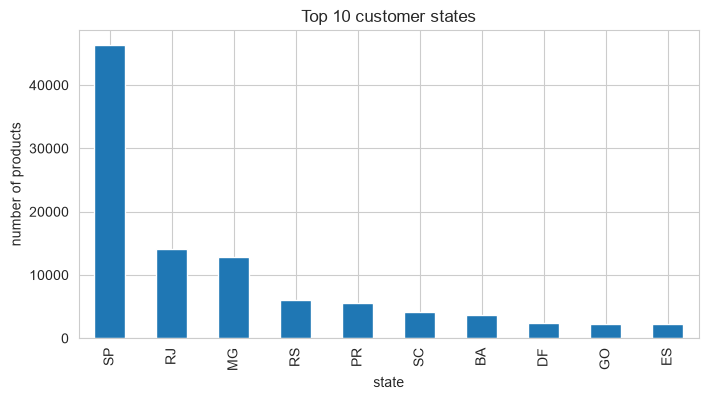

In [27]:

df['customer_state'].value_counts().head(10).plot(kind='bar', figsize=(8, 4), title='Top 10 customer states')
plt.xlabel('state')
plt.ylabel('number of products')
plt.show()



### Figure 7: Where are the sellers?


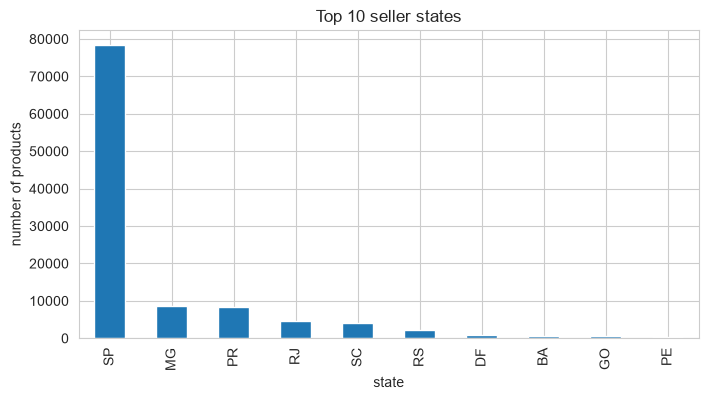

In [28]:

df['seller_state'].value_counts().head(10).plot(kind='bar', figsize=(8, 4), title='Top 10 seller states')
plt.xlabel('state')
plt.ylabel('number of products')
plt.show()


In [29]:

df['purchase_month'] = df['order_purchase_timestamp'].dt.month
df['purchase_weekday'] = df['order_purchase_timestamp'].dt.dayofweek    # 0 = Monday
df['purchase_hour'] = df['order_purchase_timestamp'].dt.hour

month_names = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun', 7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
weekday_names = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}



# What makes delivery slower? (relationship with delivery time)


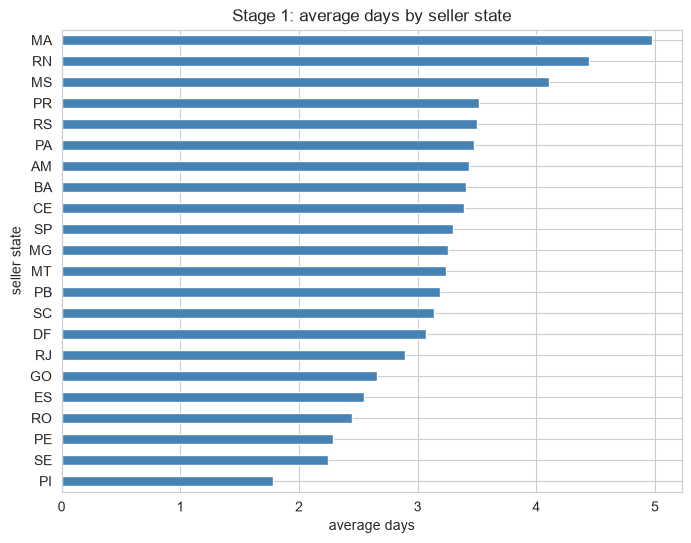

In [30]:

df.groupby('seller_state')[t1].mean().sort_values().plot(kind='barh', figsize=(8, 6), color='steelblue', title='Stage 1: average days by seller state')
plt.xlabel('average days')
plt.ylabel('seller state')
plt.show()



### Figure 9: Which customer states wait longest for the carrier? (Stage 2)


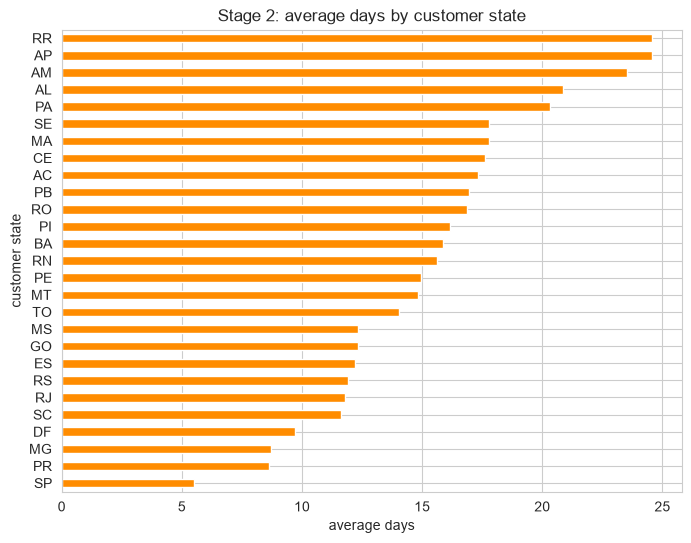

In [31]:

df.groupby('customer_state')[t2].mean().sort_values().plot(kind='barh', figsize=(8, 6), color='darkorange', title='Stage 2: average days by customer state')
plt.xlabel('average days')
plt.ylabel('customer state')
plt.show()



### Figure 10: Which routes are the slowest? (15 most common routes)


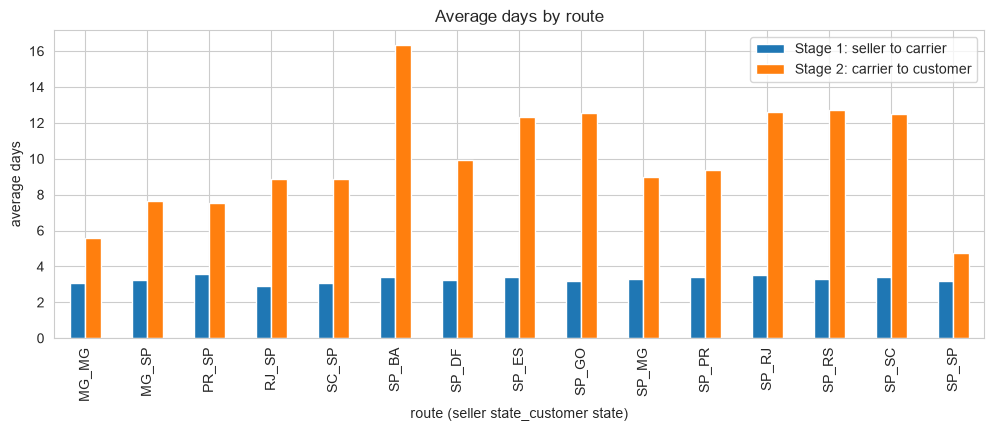

In [32]:

top_routes = df['state_route'].value_counts().head(15).index

df[df['state_route'].isin(top_routes)].groupby('state_route')[[t1, t2]].mean().rename(columns=target_names).plot(
    kind='bar', figsize=(12, 4), title='Average days by route')
plt.xlabel('route (seller state_customer state)')
plt.ylabel('average days')
plt.legend(bbox_to_anchor=(1, 1))     
plt.show()



### Figure 11: Do some product categories take longer? (15 most sold categories)


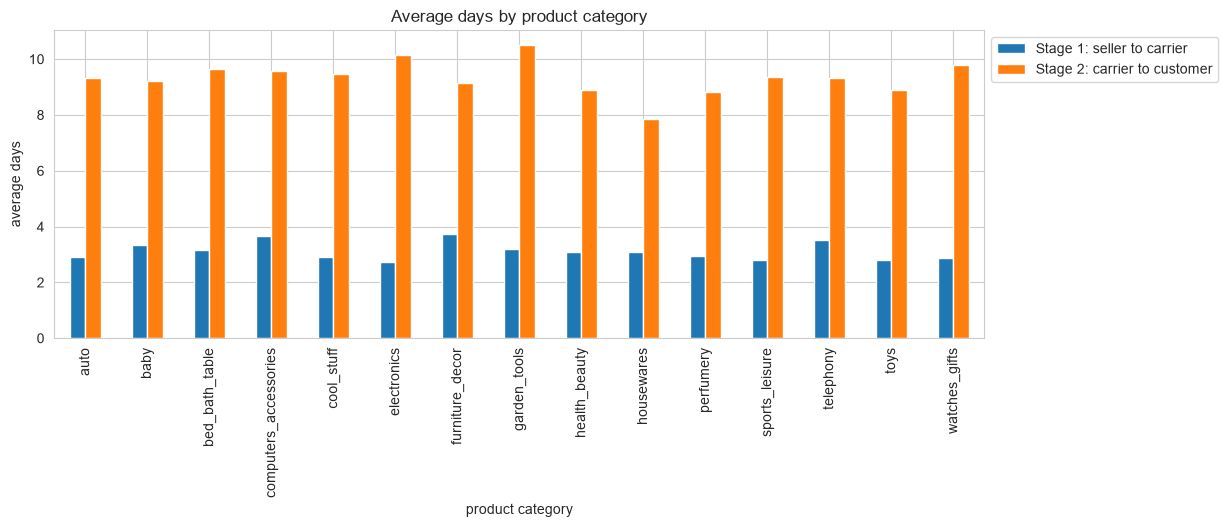

In [33]:

top_categories = df['product_category_name_english'].value_counts().head(15).index

df[df['product_category_name_english'].isin(top_categories)].groupby('product_category_name_english')[[t1, t2]].mean().rename(columns=target_names).plot(
    kind='bar', figsize=(12, 4), title='Average days by product category')
plt.xlabel('product category')
plt.ylabel('average days')
plt.legend(bbox_to_anchor=(1, 1))      
plt.show()



### Figure 12: Do heavier products take longer?


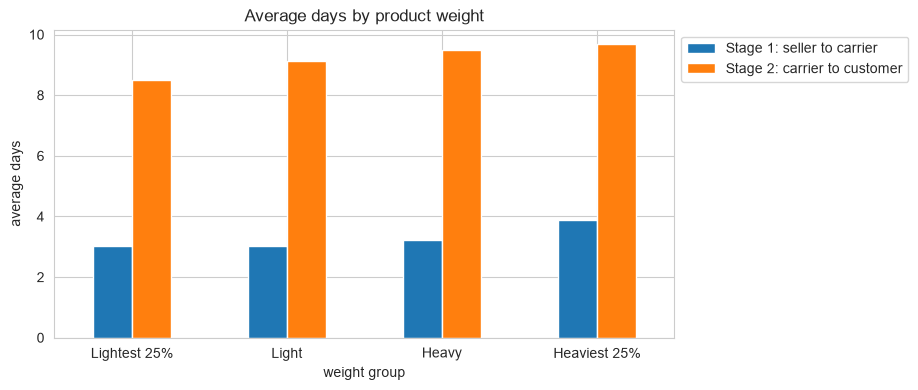

In [34]:

groups = pd.qcut(df['product_weight_g'].rank(method='first'), 4, labels=['Lightest 25%', 'Light', 'Heavy', 'Heaviest 25%'])

df.groupby(groups, observed=True)[[t1, t2]].mean().rename(columns=target_names).plot(kind='bar', figsize=(8, 4), title='Average days by product weight')
plt.xlabel('weight group')
plt.ylabel('average days')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1, 1))      
plt.show()



### Figure 13: Do more expensive products take longer?


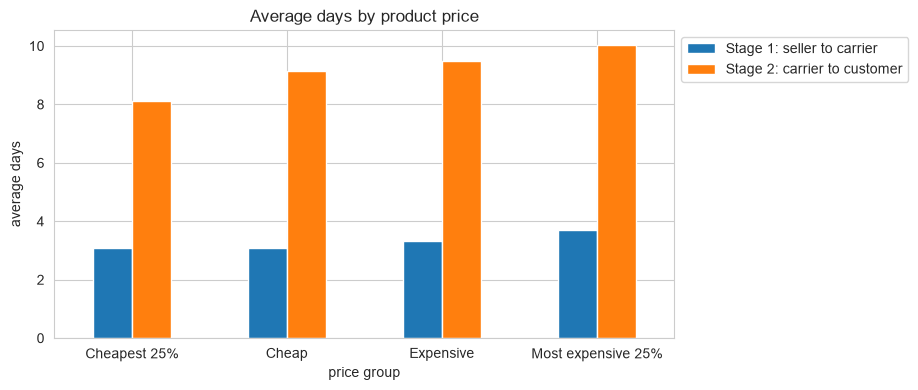

In [35]:

groups = pd.qcut(df['price'].rank(method='first'), 4, labels=['Cheapest 25%', 'Cheap', 'Expensive', 'Most expensive 25%'])

df.groupby(groups, observed=True)[[t1, t2]].mean().rename(columns=target_names).plot(kind='bar', figsize=(8, 4), title='Average days by product price')
plt.xlabel('price group')
plt.ylabel('average days')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1, 1))      
plt.show()



### Figure 14: Does a higher shipping cost mean a longer delivery?


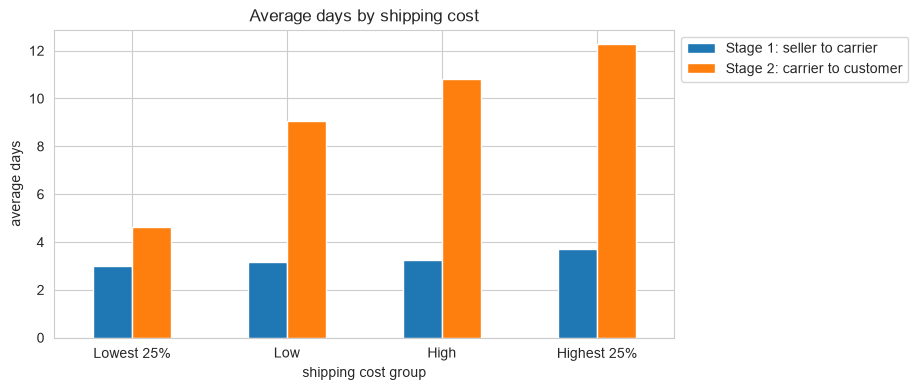

In [36]:

groups = pd.qcut(df['freight_value'].rank(method='first'), 4, labels=['Lowest 25%', 'Low', 'High', 'Highest 25%'])

df.groupby(groups, observed=True)[[t1, t2]].mean().rename(columns=target_names).plot(kind='bar', figsize=(8, 4), title='Average days by shipping cost')
plt.xlabel('shipping cost group')
plt.ylabel('average days')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1, 1))
plt.show()



### Figure 15: Does the day of the week matter?


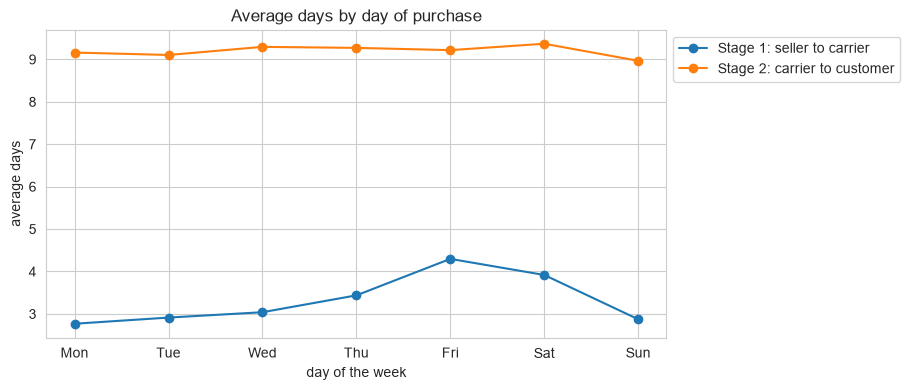

In [37]:

df.groupby('purchase_weekday')[[t1, t2]].mean().rename(index=weekday_names, columns=target_names).plot(marker='o', figsize=(8, 4), title='Average days by day of purchase')
plt.xlabel('day of the week')
plt.ylabel('average days')
plt.legend(bbox_to_anchor=(1, 1))      
plt.show()



### Figure 16: Does the month of purchase matter?


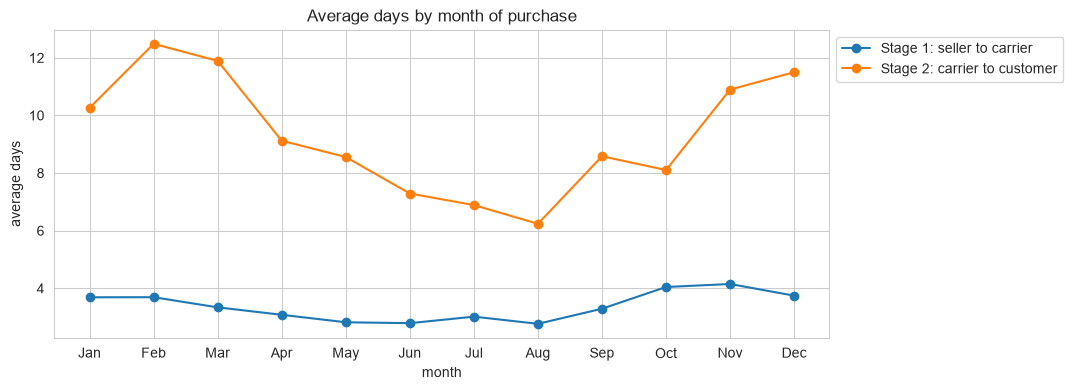

In [38]:

df.groupby('purchase_month')[[t1, t2]].mean().rename(index=month_names, columns=target_names).plot(marker='o', figsize=(10, 4), title='Average days by month of purchase')
plt.xlabel('month')
plt.ylabel('average days')
plt.xticks(range(12), list(month_names.values()))      
plt.legend(bbox_to_anchor=(1, 1))     
plt.show()



### Figure 17: Does the hour of purchase matter?


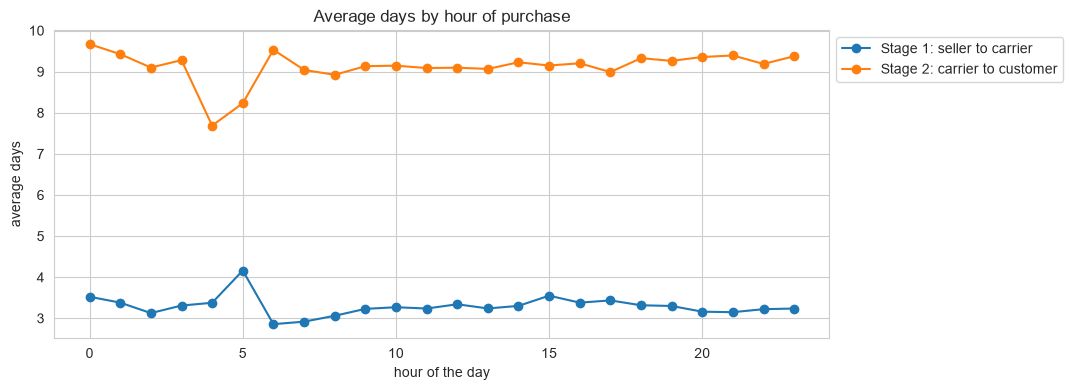

In [39]:

df.groupby('purchase_hour')[[t1, t2]].mean().rename(columns=target_names).plot(marker='o', figsize=(10, 4), title='Average days by hour of purchase')
plt.xlabel('hour of the day')
plt.ylabel('average days')
plt.legend(bbox_to_anchor=(1, 1))      
plt.show()



### Figure 18: Which features are linked to delivery time?

A bar close to **0** means almost no link. A bar close to **+1 or -1** means a strong link.


In [40]:

feature_names = {'product_weight_g': 'Product weight', 'product_length_cm': 'Product length',
                 'product_height_cm': 'Product height', 'product_width_cm': 'Product width',
                 'price': 'Price', 'freight_value': 'Shipping cost (freight)',
                 'purchase_month': 'Purchase month', 'purchase_weekday': 'Purchase day of week',
                 'purchase_hour': 'Purchase hour'}

link = df[list(feature_names) + [t1, t2]].corr()[[t1, t2]].drop([t1, t2])


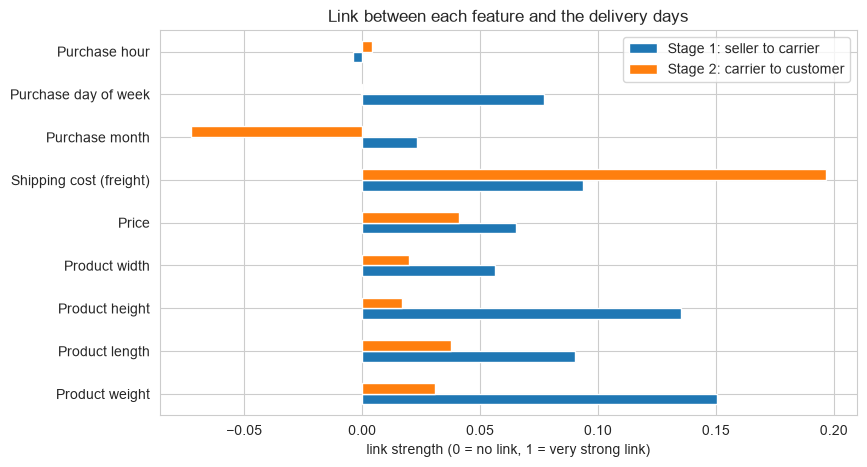

In [41]:

link.rename(index=feature_names, columns=target_names).plot(kind='barh', figsize=(9, 5), title='Link between each feature and the delivery days')
plt.xlabel('link strength (0 = no link, 1 = very strong link)')
plt.legend(bbox_to_anchor=(1, 1))     
plt.show()



### Figure 19: Heatmap - how are all the numbers linked to each other?


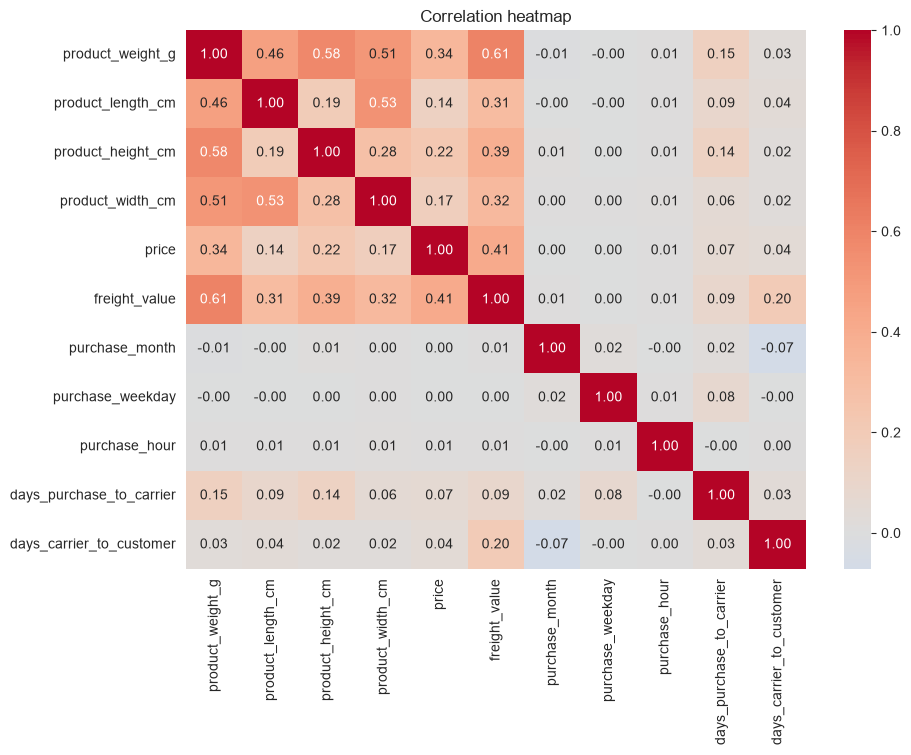

In [42]:

corr_cols = num_features + ['purchase_month', 'purchase_weekday', 'purchase_hour', t1, t2]

plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap')
plt.show()


### Save

In [43]:
df['product_volume_cm3'] = df['product_length_cm'] * df['product_height_cm'] * df['product_width_cm']
df['shipping_limit_date'] = pd.to_datetime(df['shipping_limit_date'])
main_item = (df.sort_values(['order_id', 'price'], ascending=[True, False]).drop_duplicates('order_id')
               [['order_id', 'product_category_name_english', 'seller_state', 'seller_city', 'seller_zip_code_prefix']]
               .rename(columns={'product_category_name_english': 'main_product_category'}))
items_agg = df.groupby('order_id').agg(
    n_items=('order_item_id', 'count'),
    n_unique_products=('product_id', 'nunique'),
    n_sellers=('seller_id', 'nunique'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    total_weight_g=('product_weight_g', 'sum'),
    max_item_weight_g=('product_weight_g', 'max'),
    total_volume_cm3=('product_volume_cm3', 'sum'),
    avg_photos_qty=('product_photos_qty', 'mean'),
    avg_description_length=('product_description_lenght', 'mean'),
    shipping_limit_date=('shipping_limit_date', 'min')).reset_index()

items_agg['freight_ratio'] = items_agg['total_freight'] / items_agg['total_price'].replace(0, np.nan)

In [44]:
payments_agg = payments_df.groupby('order_id').agg(
    total_payment_value=('payment_value', 'sum'),
    max_installments=('payment_installments', 'max'),
    n_payment_methods=('payment_type', 'nunique')).reset_index()

main_payment = (payments_df.sort_values(['order_id', 'payment_value'], ascending=[True, False]).drop_duplicates('order_id')
                [['order_id', 'payment_type']].rename(columns={'payment_type': 'main_payment_type'}))

payments_agg = payments_agg.merge(main_payment, on='order_id', how='left')

NameError: name 'payments_df' is not defined

In [ ]:
model_df = (orders_df.merge(customers_df, on='customer_id', how='left')
                     .merge(items_agg, on='order_id', how='inner')
                     .merge(main_item, on='order_id', how='left')
                     .merge(payments_agg, on='order_id', how='left'))

purchase = model_df['order_purchase_timestamp']
model_df['purchase_year'] = purchase.dt.year
model_df['purchase_month'] = purchase.dt.month
model_df['purchase_dayofweek'] = purchase.dt.dayofweek
model_df['purchase_hour'] = purchase.dt.hour
model_df['is_weekend'] = (model_df['purchase_dayofweek'] >= 5).astype(int)
model_df['approval_lag_hours'] = (model_df['order_approved_at'] - purchase).dt.total_seconds() / 3600
model_df['seller_deadline_days'] = (model_df['shipping_limit_date'] - purchase).dt.total_seconds() / 86400
model_df['estimated_delivery_days'] = (model_df['order_estimated_delivery_date'] - purchase).dt.total_seconds() / 86400

model_df['same_state'] = (model_df['customer_state'] == model_df['seller_state']).astype(int)
model_df['same_city'] = (model_df['customer_city'].str.lower() == model_df['seller_city'].str.lower()).astype(int)
model_df['state_route'] = model_df['seller_state'] + '->' + model_df['customer_state']

model_df['delivery_days'] = (model_df['order_delivered_customer_date'] - purchase).dt.total_seconds() / 86400

In [ ]:
final_cols = ['order_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'n_items', 'n_unique_products',
              'n_sellers', 'total_price', 'total_freight', 'total_weight_g', 'max_item_weight_g', 'total_volume_cm3',
              'avg_photos_qty', 'avg_description_length', 'freight_ratio', 'main_product_category', 'seller_state',
              'seller_city', 'seller_zip_code_prefix', 'total_payment_value', 'max_installments', 'n_payment_methods',
              'main_payment_type', 'purchase_year', 'purchase_month', 'purchase_dayofweek', 'purchase_hour', 'is_weekend',
              'approval_lag_hours', 'seller_deadline_days', 'estimated_delivery_days', 'same_state', 'same_city',
              'state_route', 'delivery_days']

olist_delivery_model_dataset = model_df[final_cols]

print('shape:', model_df.shape, '| duplicate orders:', model_df['order_id'].duplicated().sum())
model_df.isna().sum()[model_df.isna().sum() > 0]

In [ ]:

olist_delivery_model_dataset.to_csv('olist_delivery_model_dataset2.csv', index=False)